In [2]:
# Parameters
HOST = "m4-macbook-air"


In [3]:
import warnings
from IPython.display import Markdown, display
import matplotlib.pyplot as plt
import pandas as pd

from benchlib import load, plots, random_suite as rs, traffic_suite as ts
from benchlib.hosts import HOSTS, REFERENCE

warnings.filterwarnings("ignore", category=RuntimeWarning)
plots.style()
pd.set_option("display.precision", 1)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", None)


def show(fig):
    if fig is not None:
        display(fig)
        plt.close(fig)

d = load.load(HOST)
h = d.host
R, T = d.random, d.traffic

In [4]:
lines = [
    f"# {h.name}: benchmark report",
    "",
    f"- **Machine:** {h.hardware}; {h.os}; cooling: {h.cooling}",
    f"- **Docker:** {h.docker}, resources **{h.resources}**",
]
for name, suite in (("Idle capacity (`random`)", R), ("Traffic limits (`traffic`)", T)):
    if suite is None:
        continue
    m = suite.manifest
    lines.append(
        f"- **{name}:** `{suite.dir.name}`, AE3GIS `{m['git']['commit'][:8]}`, "
        f"{str(m.get('started_at', ''))[:10]} → {str(m.get('ended_at') or '')[:10] or 'running'}"
    )
if T is not None:
    lines.append(f"- **Traffic cells final:** {int(T.cells['done'].sum())} of {len(T.cells)}")
if h.deviations:
    lines += ["", "**Settings that differ from the shared suites:**", ""] + [f"- {x}" for x in h.deviations]
if h.issues:
    lines += ["", "**Read these numbers with:**", ""] + [f"- {x}" for x in h.issues]
lines += ["", f"Notes from the run: `backend/benchmark-results/{h.key}/NOTES.md`."]
display(Markdown("\n".join(lines)))

# M4 MacBook Air: benchmark report

- **Machine:** MacBook Air 15" (Mac16,13), Apple M4 (4P + 6E cores), 32 GB; macOS 26.7.1; cooling: fanless
- **Docker:** Docker Desktop 4.95.0 (Docker 29.8.2), resources **8 CPUs / 16.7 GB**
- **Idle capacity (`random`):** `2026-10-06-random`, AE3GIS `0c8ac80e`, 2026-10-06 → 2026-10-06
- **Traffic limits (`traffic`):** `2026-10-07-traffic`, AE3GIS `9517ee62`, 2026-10-07 → 2026-10-16
- **Traffic cells final:** 90 of 100

**Read these numbers with:**

- Traffic: measured with the old traffic driver until 2026-10-12, then the fixed one; 54 cells were searched again after the fix and 13 more after the memory-stall re-check (2026-10-19). 10 cells are still open (paused).
- Traffic cells rest before running (a quiet host, then an idle minute) because the fanless chip throttled under back-to-back heavy cells.

Notes from the run: `backend/benchmark-results/m4-macbook-air/NOTES.md`.

In [5]:
# Sanity checks: the data is complete and matches what the runner wrote.
import json
assert R is not None and len(R.climbs) == 10, "10 random climbs"
assert T is not None and len(T.cells) == 100, "100 traffic cells"
ref = T.dir / "limits-burst-limits.json"
if T.cells["done"].all() and ref.exists():
    want = {r["id"]: (r["comfortable"], r["fails_at"]) for r in json.loads(ref.read_text())}
    got = {c.cell: (None if pd.isna(c.comfortable) else int(c.comfortable),
                    None if pd.isna(c.fails_at) else int(c.fails_at)) for c in T.cells.itertuples()}
    assert got == {k: tuple(v) for k, v in want.items()}, "grids match limits-burst-limits.json"
print("checks passed:", len(R.climbs), "climbs,", len(T.cells), "traffic cells,",
      int(T.cells["done"].sum()), "final")

checks passed: 10 climbs, 100 traffic cells, 90 final


## 1. Idle capacity (`random` suite)

How many nodes this host holds when they only idle.
- **Census:** deploys each node type · image on its own, to see what one node costs and which images run here.
- **Climbs:** 10 climbs deploy a random mix of every type (equal odds, then an image of that type) at growing sizes, until a limit stops them (memory, a deploy that fails or takes too long, disk). The largest size that passed is the climb's **ceiling**.

Every climb counts in the statistics. Climbs with known problems are greyed and annotated.

### Census: what one node of each image costs

type,image,usable,outcome,reason,host_mb_per_node,cgroup_mb_per_node,deploy_s,ready_s,disk_mb_per_node
workstation,ae3gis.local/firefox,True,ok,–,421.6,515.0,2.2,0.05,35.9
ids,ae3gis.local/suricata,True,ok,–,70.1,67.9,1.5,0.03,0.4
plc,ae3gis.local/openplc,True,ok,–,47.5,57.5,2.0,0.05,0.6
database-server,postgres:alpine,True,ok,–,37.8,38.7,2.1,0.02,41.0
web-server,httpd:alpine,True,ok,–,32.1,6.1,1.7,0.03,0.4
web-server,ae3gis.local/nginx,True,ok,–,23.0,10.0,1.5,0.02,0.4
firewall,ae3gis.local/firehol,True,ok,–,17.2,4.7,1.7,0.00,0.4
switch,kathara/base,True,ok,–,16.9,1.2,1.5,0.00,0.5
web-server,ae3gis.local/apache,True,ok,–,16.2,10.2,1.6,0.02,0.4
firewall,ae3gis.local/iptables,True,ok,–,14.8,5.0,1.4,0.00,0.4


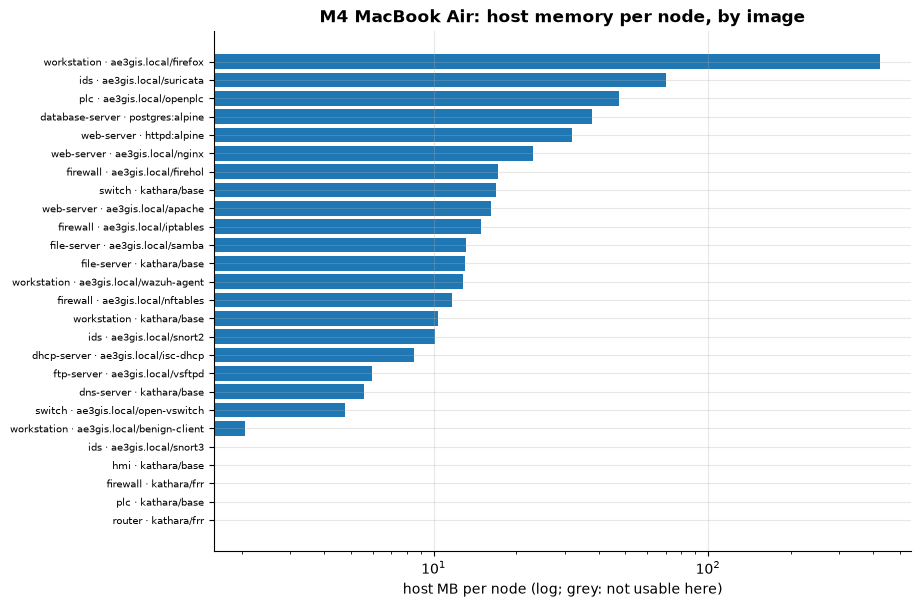

In [6]:
c = rs.census_table(R)
display(c.style.format({"host_mb_per_node": "{:.1f}", "cgroup_mb_per_node": "{:.1f}", "deploy_s": "{:.1f}",
                        "ready_s": "{:.2f}", "disk_mb_per_node": "{:.1f}"}, na_rep="–").hide(axis="index"))
show(plots.census_bars(c, f"{h.name}: host memory per node, by image"))

The census deploys only 5 nodes per image, so for light images the host figure above is mostly the lab's fixed overhead. Each image's **container memory**, measured over every container at the climbs' ceilings (hundreds of nodes), is the sturdier per-image cost:

In [7]:
im = rs.image_memory(R).sort_values(ascending=False).rename("container MB (median over climbs)")
display(im.to_frame().T.style.format("{:.1f}"))

image,ae3gis.local/firefox,ae3gis.local/suricata,ae3gis.local/openplc,postgres:alpine,ae3gis.local/open-vswitch,ae3gis.local/nginx,ae3gis.local/apache,ae3gis.local/samba,httpd:alpine,ae3gis.local/vsftpd,ae3gis.local/firehol,ae3gis.local/nftables,ae3gis.local/snort3,ae3gis.local/iptables,ae3gis.local/snort2,ae3gis.local/benign-client,ae3gis.local/wazuh-agent,kathara/frr,kathara/base,ae3gis.local/isc-dhcp
container MB (median over climbs),391.6,57.4,47.9,28.3,19.9,8.7,8.5,7.8,4.9,3.3,3.1,2.7,2.7,2.7,2.7,2.6,2.0,1.2,1.2,1.2


### Climbs

**Ceiling over all 10 climbs: 530 ± 73 hosts** (range 450–700).

,seed,ceiling,nodes,mem_pct,mb_per_node,deploy_s_per_node,stop,note
climb,,,,,,,,
1,1,490,510,90.7,24.2,0.35,memory,
2,2,560,582,90.1,20.4,0.36,memory,
3,3,450,470,91.2,28.0,0.27,memory,
4,4,460,480,90.4,26.2,0.38,memory,
5,5,500,521,90.1,23.6,0.31,memory,
6,6,490,510,90.1,24.4,0.28,memory,
7,7,700,728,90.4,16.3,0.38,memory,
8,8,530,551,91.2,23.1,0.32,memory,
9,9,540,561,90.3,21.7,0.35,memory,


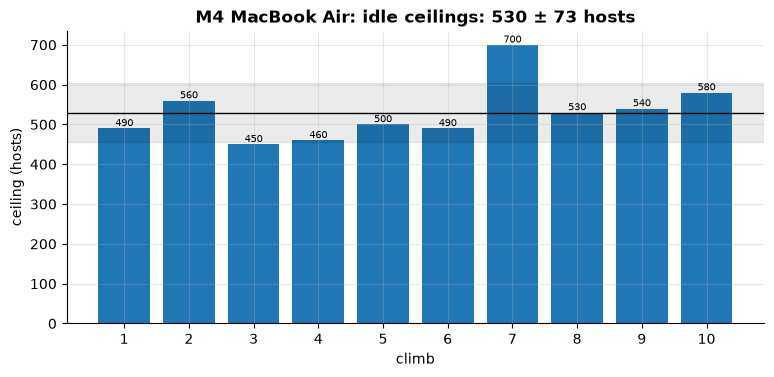

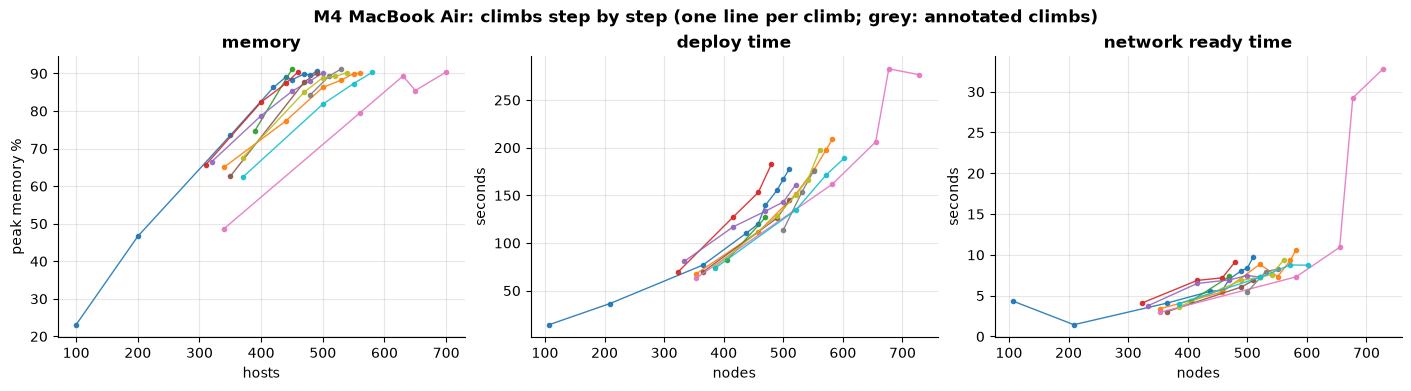

In [8]:
st = rs.ceiling_stats(R)
display(Markdown(f"**Ceiling over all {st['climbs']:.0f} climbs: {st['mean']:.0f} ± {st['std']:.0f} hosts** "
                 f"(range {st['min']:.0f}–{st['max']:.0f})."))
t = rs.climb_table(R).assign(stop=rs.climb_stops(R).values)
display(t[["seed", "ceiling", "nodes", "mem_pct", "mb_per_node", "deploy_s_per_node", "stop", "note"]]
        .style.format({"mem_pct": "{:.1f}", "mb_per_node": "{:.1f}", "deploy_s_per_node": "{:.2f}"}, na_rep="–"))
show(plots.ceilings(R.climbs, h.color, f"{h.name}: idle ceilings"))
show(plots.trajectories(R.steps, R.climbs, f"{h.name}: climbs step by step"))

### What drives the spread between climbs

Each climb draws a different mix. The scatter below sets its ceiling against what one node of that mix costs, from the census. The table lists the images whose share of the mix moves the ceiling most.

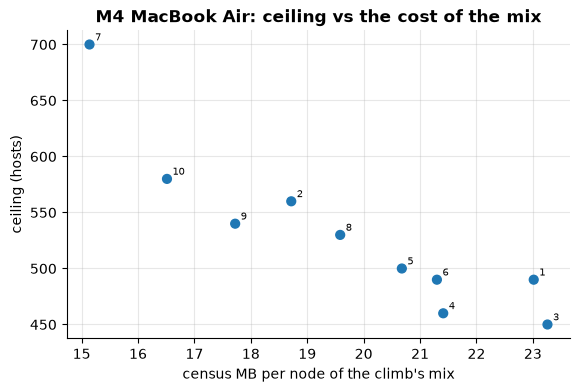

case,corr_with_ceiling,share_min_pct,share_max_pct,count_min,count_max,host_mb_per_node
workstation · ae3gis.local/firefox,-0.93,0.700000,2.800000,5,13,421.6
web-server · ae3gis.local/nginx,+0.61,1.300000,3.200000,7,19,23.0
dhcp-server · ae3gis.local/isc-dhcp,+0.56,5.100000,8.700000,26,63,8.5


In [9]:
cc = rs.composition_cost(R)
show(plots.ceiling_vs_mix(cc, h.color, f"{h.name}: ceiling vs the cost of the mix"))
display(rs.drivers(R).style.format({"corr_with_ceiling": "{:+.2f}", "host_mb_per_node": "{:.1f}"}).hide(axis="index"))

### Share of each type at the ceiling (%)

In [10]:
display(rs.type_shares(R).T)

,switch,firewall,ftp-server,hmi,database-server,dns-server,router,ids,file-server,plc,workstation,web-server,dhcp-server
mean,10.4,8.1,7.8,7.7,7.6,7.5,7.4,7.4,7.3,7.3,7.2,7.2,7.0
std,0.5,0.8,0.7,1.1,1.2,1.1,1.0,0.5,1.1,1.2,1.1,1.1,1.3


## 2. Traffic limits (`traffic` suite)

100 cells: 5 rates × 5 burst intervals × TCP/UDP × two patterns.
- **clients → servers:** one flow per host, north–south through the routers and core.
- **mesh:** two flows per host, east–west inside a LAN.

For each cell, the search finds the most hosts whose traffic still gets through (≥ 95% delivered, ≤ 1% UDP loss) and where it fails, 50 hosts apart; the comfortable size passes twice. Grid markers:
- `mem`: a host limit (memory, a deploy that failed or took too long), not traffic;
- `tool`: clients not started in time;
- `≥ N`: never failed up to N;
- `…`: still being searched.

In [11]:
display(ts.overview(T).to_frame('').style)

,
cells final,90 of 100
probes (lab sizes measured),182
rounds,23
cell runs,685
cell runs by the fixed driver,267
results dropped (re-check / repair),212
re-check rules applied,"coverage, unstarted, stalls"
started,2026-10-07 23:41
last update,2026-10-19 17:39


### Limits: comfortable / fails at (hosts)

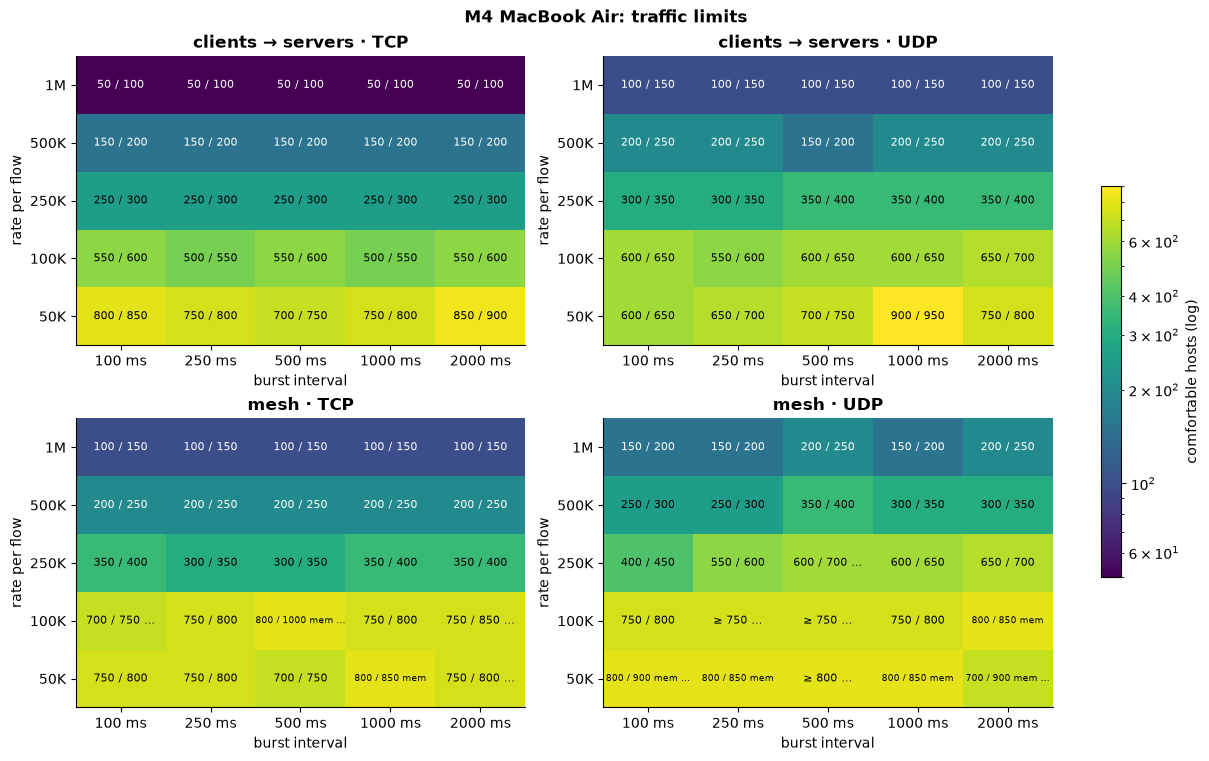

In [12]:
show(plots.limit_heatmaps(T.cells, f"{h.name}: traffic limits"))

### Traffic carried at the comfortable size (Mb/s offered = hosts × rate × flows per host)

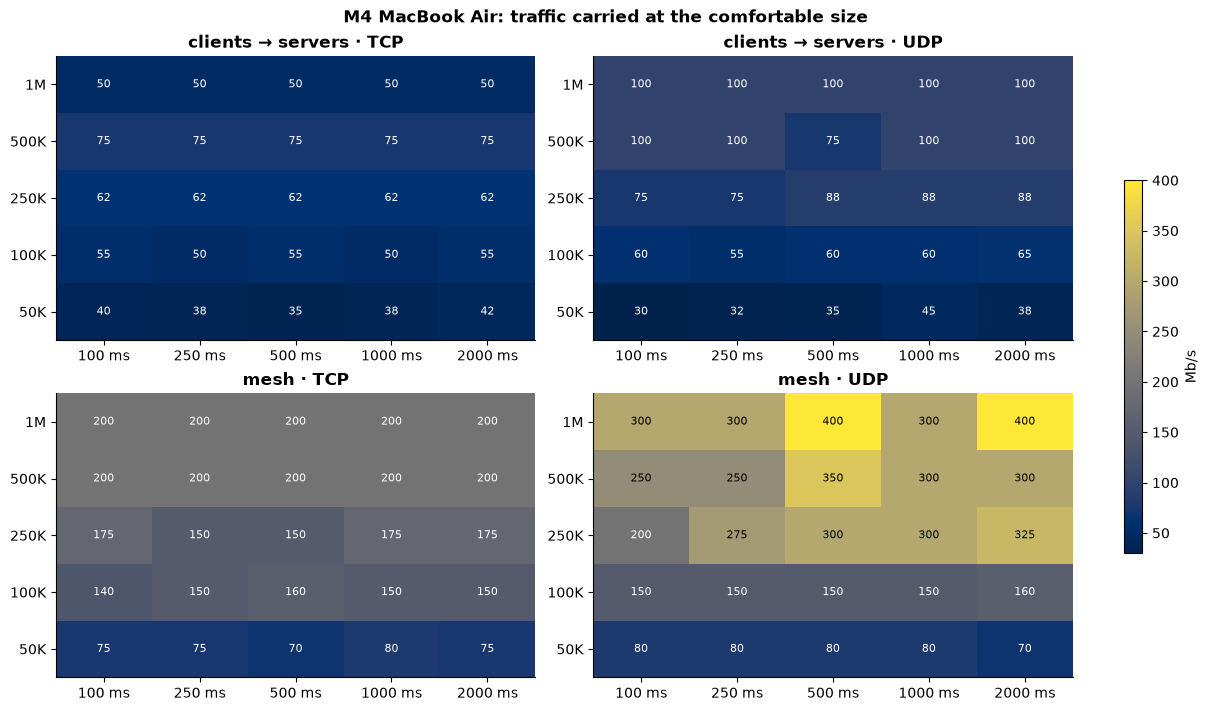

In [13]:
grids = {s: ts.grid(T.cells, s, "carried_mbps") for s in ts.SCENARIO_ORDER}
show(plots.value_heatmaps(grids, f"{h.name}: traffic carried at the comfortable size", unit="Mb/s", cmap="cividis"))

### What the traffic costs

How much of the host's CPU the lab's containers use per 100 Mb/s delivered, by scenario and lab size (passing runs). On one machine it should be roughly flat.

A cost that falls with lab size is the signature of partial load: under the old driver, big labs' clients were still starting during the measured window. Nodes receive each delivered byte several times: once per hop.

bin,0–250,250–450,450–650,650–850,850–1100
scenario,,,,,
cs·tcp,7.52,9.46,11.16,14.71,10.75
cs·udp,4.25,4.71,5.40,6.55,5.67
mesh·tcp,2.63,3.32,3.73,4.32,6.95
mesh·udp,1.68,1.87,2.01,2.31,2.08


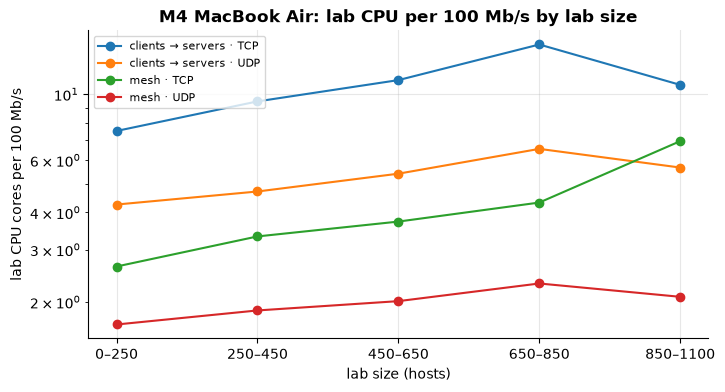

scenario,cs·tcp,cs·udp,mesh·tcp,mesh·udp
node receives per delivered byte,6.5,6.1,2.3,2.1


In [14]:
cost = ts.cost_by_size(T.rows)
display(cost.style.format("{:.2f}", na_rep="–"))
show(plots.cost_lines(cost, f"{h.name}: lab CPU per 100 Mb/s by lab size"))
k = ts.kept(T.rows)
display(k[k["outcome"] == "ok"].groupby("scenario")["rx_per_delivered"].median()
        .rename("node receives per delivered byte").to_frame().T.style.format("{:.1f}"))

### What set each cell's limit

In [15]:
display(ts.reasons(T.cells))
f = ts.at_limit(T, "fails")
if not f.empty:
    display(f.groupby(["scenario", "reason"])[["cpu_pct", "mem_pct", "delivered_ratio", "loss_pct"]]
            .median().style.format({"cpu_pct": "{:.0f}", "mem_pct": "{:.0f}", "delivered_ratio": "{:.0%}",
                                    "loss_pct": "{:.1f}"}, na_rep="–")
            .set_caption("At the size each cell fails at (medians)"))

kind,delivery,loss,memory,never failed (≥),not reached
scenario,,,,,
cs·tcp,25,0,0,0,0
cs·udp,13,12,0,0,0
mesh·tcp,23,0,2,0,0
mesh·udp,17,0,3,3,2


### Latency (TCP) and loss (UDP) at the comfortable size

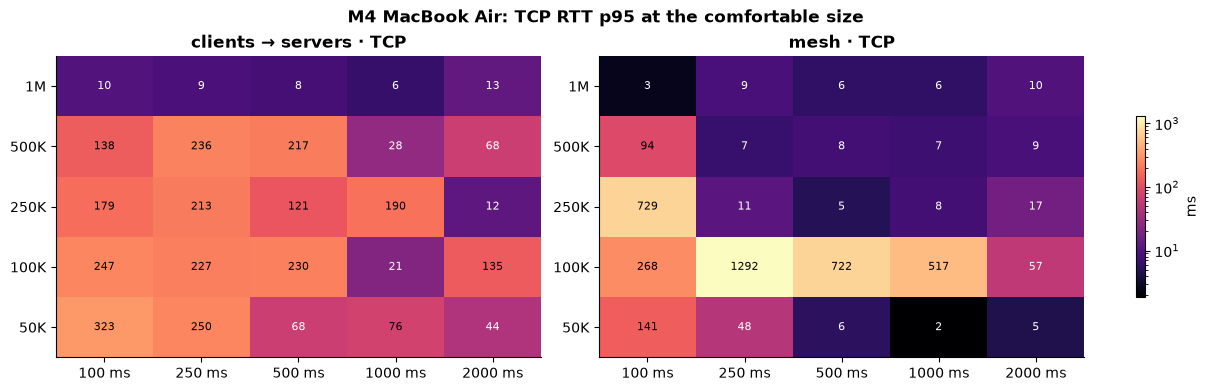

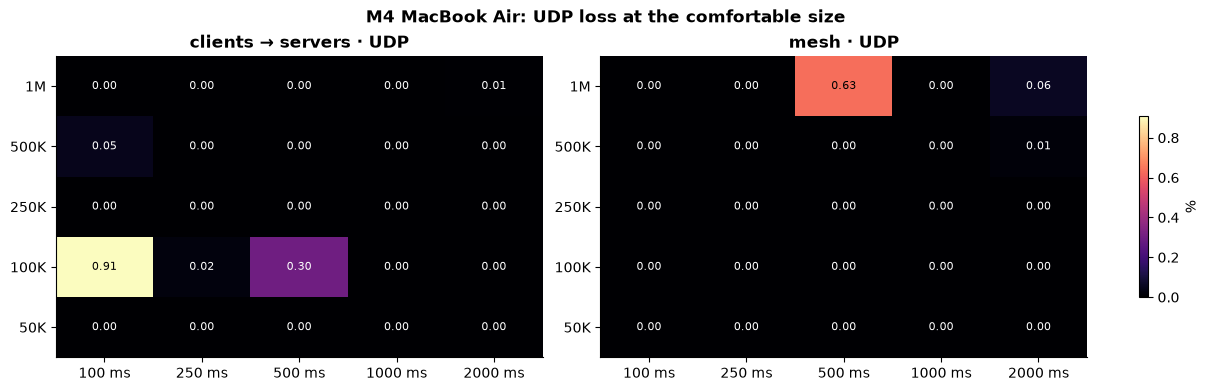

In [16]:
ok = ts.at_limit(T, "comfortable")
if not ok.empty:
    pivot = lambda s, v: ok[ok["scenario"] == s].pivot(index="rate", columns="interval_ms", values=v)
    show(plots.value_heatmaps({s: pivot(s, "rtt_p95_ms") for s in ("cs·tcp", "mesh·tcp")},
                              f"{h.name}: TCP RTT p95 at the comfortable size", unit="ms", log=True))
    show(plots.value_heatmaps({s: pivot(s, "loss_pct") for s in ("cs·udp", "mesh·udp")},
                              f"{h.name}: UDP loss at the comfortable size", fmt="{:.2f}", unit="%"))

### The burst interval's effect

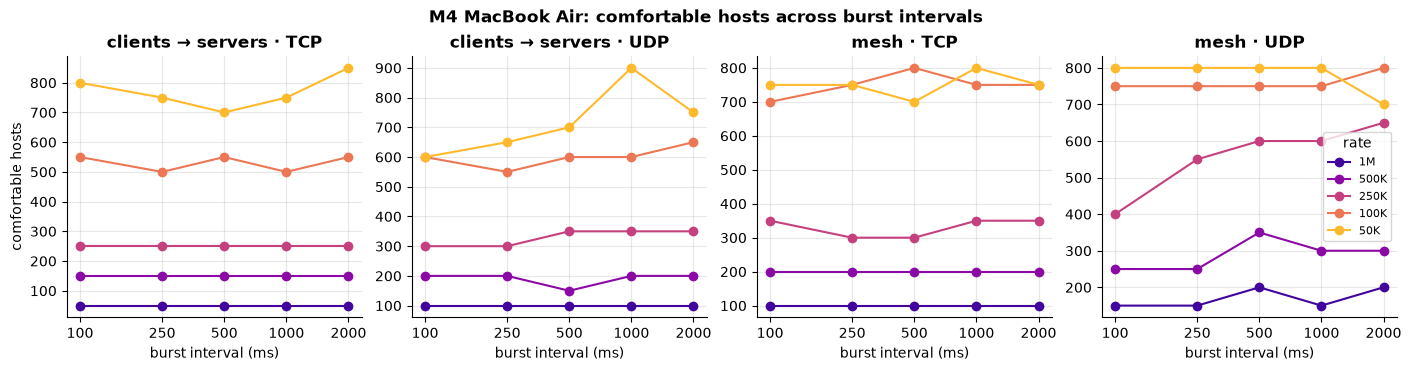

In [17]:
show(plots.interval_lines(T.cells, f"{h.name}: comfortable hosts across burst intervals"))

### What a lab costs to deploy, by size

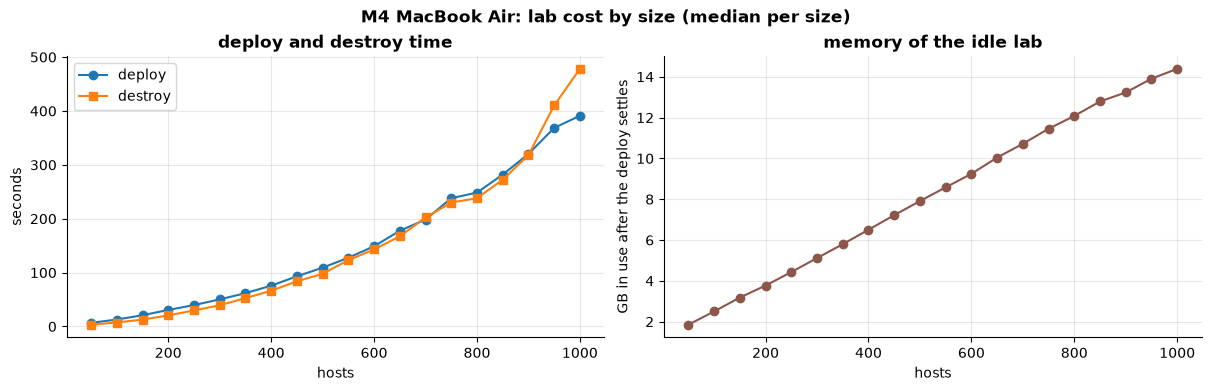

In [18]:
show(plots.deploy_costs(T.deploys, f"{h.name}: lab cost by size (median per size)"))

### How the search went (every counted probe per cell)

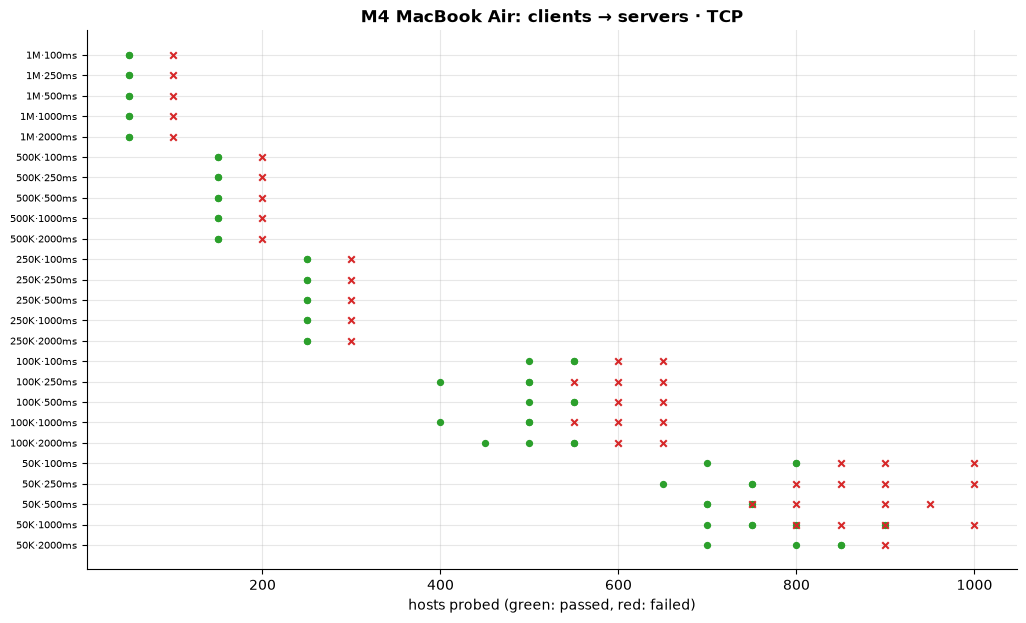

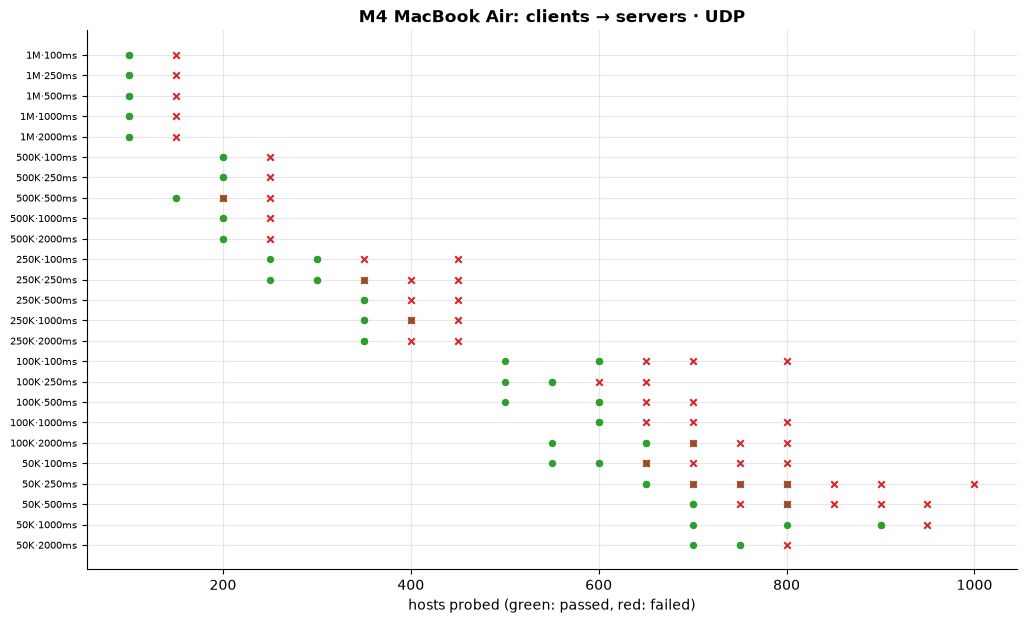

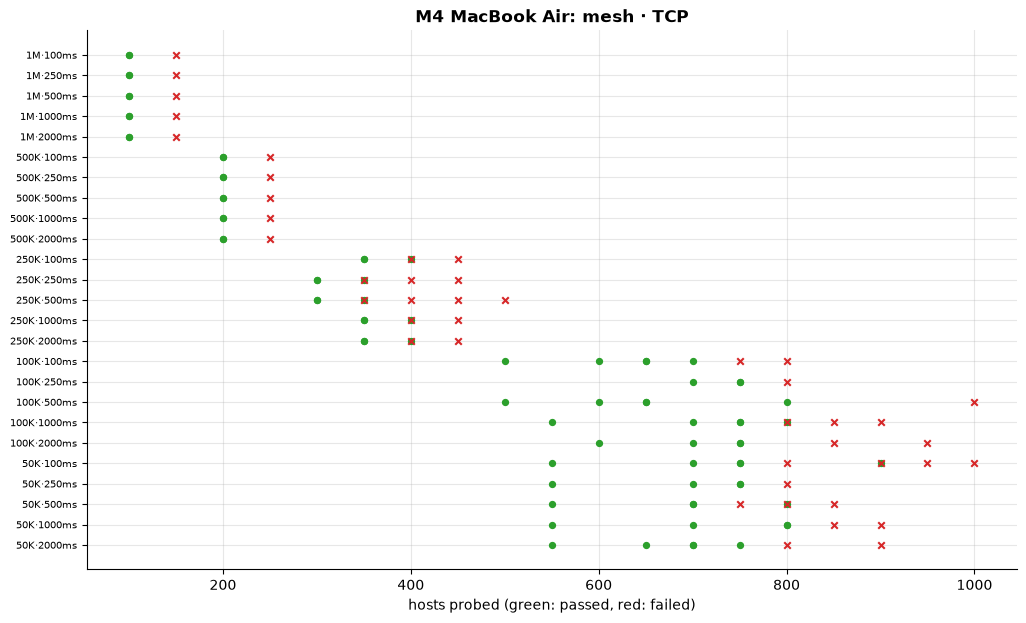

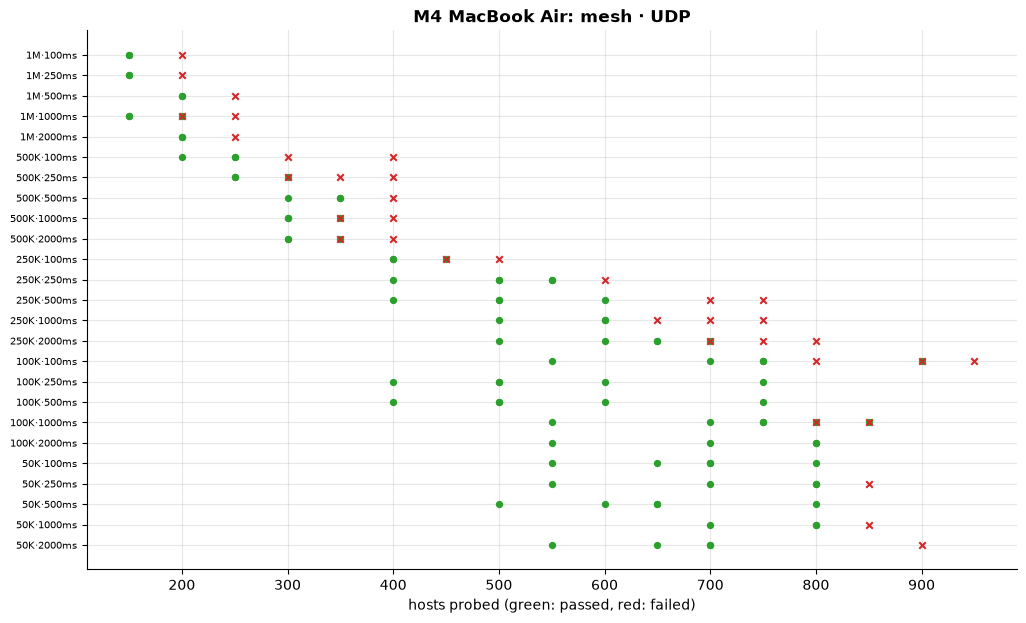

In [19]:
for s in ts.SCENARIO_ORDER:
    show(plots.search_history(ts.search_history(T, s), f"{h.name}: {plots._scenario(s)}"))

## 3. Data quality

Which traffic driver measured each run, and the old driver's symptoms in mesh labs, by lab size:
- **dead flows:** at least 5% of flows delivered nothing;
- **memory stalls:** full PSI.

Under the fixed driver every client starts before the window, so dead flows there are a real overload: clients that couldn't connect.

In [20]:
for pattern in ("mesh", "cs"):
    q = ts.quality_by_size(T.rows, pattern)
    if not q.empty:
        display(q.style.format({"dead_flows_pct": "{:.0f}", "psi_mem_full_median": "{:.1f}",
                                "mem_pct_median": "{:.0f}"}).set_caption(f"{pattern} labs"))
if len(T.dropped):
    display(T.dropped.groupby(["by", "why"]).size().rename("results dropped").to_frame())

results dropped
by       why                                                          
re-check failure from clients that never ran                        30
         failure under the old driver's memory stalls               25
         never reached                                               5
         pass at 0% full load                                        4
         pass at 10% full load                                       1
         pass at 12% full load                                       3
         pass at 13% full load                                       1
         pass at 15% full load                                       1
         pass at 16% full load                                       1
         pass at 17% full load                                       2
         pass at 20% full load                                       1
         pass at 22% full load                                       3
         pass at 23% full load                                       2
         pass at 24% full load                                       1
         pass at 27% full load                                       1
         pass at 29% full load                                       1
         pass at 3% full load                                        4
         pass at 34% full load                                       1
         pass at 35% full load                                       1
         pass at 36% full load                                       1
         pass at 39% full load                                       2
         pass at 4% full load                                        1
         pass at 40% full load                                       4
         pass at 43% full load                                       1
         pass at 44% full load                                       1
         pass at 46% full load                                       1
         pass at 47% full load                                       1
         pass at 48% full load                                       1
         pass at 50% full load                                       1
         pass at 51% full load                                       7
         pass at 53% full load                                       1
         pass at 55% full load                                       1
         pass at 56% full load                                       3
         pass at 59% full load                                       2
         pass at 60% full load                                       1
         pass at 62% full load                                       5
         pass at 63% full load                                       5
         pass at 64% full load                                       1
         pass at 65% full load                                       1
         pass at 66% full load                                       1
         pass at 68% full load                                       1
         pass at 70% full load                                       1
         pass at 71% full load                                       3
         pass at 73% full load                                       3
         pass at 74% full load                                       4
         pass at 75% full load                                       4
         pass at 76% full load                                       2
         pass at 77% full load                                       8
         pass at 78% full load                                       8
         pass at 79% full load                                       4
         pass at 80% full load                                       2
         pass at 85% full load                                       2
         pass at 86% full load                                       6
         pass at 87% full load                                      11
         pass at 88% full load                                       9
        